# Módulo 9 — Análise Espectral
## Seção 9.1 — Domínio temporal e domínio da frequência

**Objetivos de aprendizagem.** Ao final, você deverá distinguir uma trajetória temporal de sua representação por frequências; interpretar amplitude, fase e potência; explicar por que uma FFT de dados finitos não equivale automaticamente à densidade espectral populacional; e reconhecer as diferenças entre periodicidade determinística e dependência estocástica.

**Pré-requisitos.** Módulos 1 (processos estocásticos e estacionariedade), 2 (sazonalidade), 4 (autocovariância) e 8 (Fourier, DFT, FFT, amostragem). Os conceitos serão retomados conforme necessários.

**Referência principal consultada.** MORETTIN, P. A.; TOLOI, C. M. C. *Análise de séries temporais: modelos lineares univariados*, 3. ed., v. 1, cap. 14, §§14.1–14.2, pp. **357–359**; fundamentos de harmônicas no cap. 13, §§13.2–13.4, pp. **335–350**. A apresentação computacional com NumPy e a distinção didática entre amplitudes finitas e espectro populacional são complementações deste material.

---

### 1. Uma mesma série pode responder a duas perguntas diferentes

Considere observações de temperatura horária. No **domínio temporal**, desenhamos o valor contra o instante $t$ e perguntamos: *quando ocorreram elevações, rupturas, tendências ou extremos?* No **domínio da frequência**, perguntamos: *quais velocidades de oscilação contribuem mais para a variação observada?*

Esses domínios não descrevem fenômenos diferentes: são duas representações de informação relacionada, com vantagens distintas. Um gráfico temporal preserva a localização de eventos; uma decomposição global de Fourier evidencia periodicidades, mas em geral não informa **quando** uma frequência esteve presente. Essa última limitação motivará a STFT e as wavelets dos Módulos 10 e 11.

Para uma série determinística amostrada com intervalo constante $\Delta t$, considere

$$x_n=3\cos(2\pi\,0{,}10\,n)+1{,}2\cos(2\pi\,0{,}25\,n+\pi/4),\qquad n=0,\ldots,N-1.$$

A primeira componente tem período de $10$ amostras e a segunda de $4$ amostras. Se cada observação for diária, são períodos de $10$ e $4$ dias. Os períodos resultam da relação $T=1/f$, quando $f$ está medido em ciclos por amostra.

A soma pode não parecer visualmente duas senoidais. A DFT permite revelar as duas frequências porque senos e cossenos nas frequências da grade são ortogonais sobre a janela completa — fundamento desenvolvido na Seção 8.4.

### 2. Frequências e unidades: não misture escalas

Se a taxa de amostragem é $f_s=1/\Delta t$ observações por unidade de tempo, temos:

| Quantidade | Símbolo | Unidade | Relação |
|---|---|---|---|
| Frequência física | $f$ | ciclos/segundo, ciclos/dia etc. | $f=1/T$ |
| Frequência angular física | $\omega$ | radianos/unidade de tempo | $\omega=2\pi f$ |
| Frequência digital angular | $\lambda$ | radianos/amostra | $\lambda=2\pi f/f_s$ |
| Período | $T$ | unidades de tempo | $T=1/f$ |
| Frequência de Nyquist | $f_s/2$ | ciclos/unidade de tempo | limite de frequências distintas após amostragem |

A conversão $\lambda=2\pi f\Delta t$ será decisiva na Seção 9.2, pois Morettin e Toloi definem a densidade espectral sobre a frequência digital $\lambda\in[-\pi,\pi]$. Não devemos colocar uma frequência em hertz nessa fórmula sem converter a unidade.

### 3. O que a DFT calcula

Para $N$ números $x_0,\ldots,x_{N-1}$, a convenção adotada por `numpy.fft.fft` é:

$$X_k=\sum_{n=0}^{N-1}x_ne^{-2\pi i kn/N},\qquad k=0,\ldots,N-1.$$

Sua inversa é $x_n=N^{-1}\sum_{k=0}^{N-1}X_ke^{2\pi i kn/N}$. Para a frequência positiva $0<k<N/2$, com um sinal real e harmônico exatamente alinhado à grade $k/N$, a **amplitude aproximada da senoide** pode ser estimada por $2|X_k|/N$. O fator dois incorpora o par de frequências positiva e negativa. A regra não deve ser aplicada da mesma forma ao componente DC ($k=0$) nem, para $N$ par, à frequência de Nyquist ($k=N/2$).

**Por que a amplitude pode ser apenas aproximada?** Uma amostra finita equivale à multiplicação do sinal por uma janela retangular. Se uma frequência não coincide com os valores $k/N$, sua energia se distribui por várias frequências da DFT: o *vazamento espectral*. Portanto, não é seguro identificar o valor do maior bin como a amplitude exata do sinal original.

### 4. Um exemplo que podemos calcular sem Python

Para $x=(1,0,-1,0)$ e $N=4$:

$$X_0=1+0-1+0=0.$$

$$X_1=1+(-1)e^{-i\pi}=1+1=2.$$

Como $x_n$ é real, $X_3=\overline{X_1}=2$, e $X_2=0$. Portanto, a sequência é uma cossenoide de uma oscilação completa em quatro amostras: $x_n=\cos(\pi n/2)$.

A reconstrução direta verifica isso:

$$x_n=\frac14\left(2e^{i\pi n/2}+2e^{-i\pi n/2}\right)=\cos(\pi n/2).$$

Observe que a frequência digital é $\lambda=\pi/2$, e não $1/4$ radiano: $1/4$ é a frequência em **ciclos por amostra**.

### 5. Energia de um sinal e variância de um processo

O teorema de Parseval para uma sequência finita fornece:

$$\sum_{n=0}^{N-1}|x_n|^2=\frac1N\sum_{k=0}^{N-1}|X_k|^2.$$

Essa equação afirma que a energia é conservada ao trocar de representação. Porém, quando estudamos séries aleatórias, o objeto central não é apenas a energia de uma trajetória, mas a **variância do processo**, distribuída pelas frequências. A Seção 9.2 fará essa passagem pela transformada de Fourier da **função de autocovariância**, conforme §14.2 do livro.

Para um processo com média $\mu$ e autocovariância $\gamma(h)=\operatorname{Cov}(X_t,X_{t+h})$, a função $\gamma(h)$ descreve como as observações se relacionam no domínio temporal. Sua transformada apropriada, sob hipóteses técnicas, produz a **densidade espectral teórica** $f(\lambda)$.

> **Distinção metodológica.** A FFT é um algoritmo aplicado a uma sequência observada. A densidade espectral é uma propriedade de segunda ordem do processo estocástico. O periodograma, apresentado no Módulo 9, será um estimador construído a partir da DFT; ele não deve ser confundido diretamente com a densidade populacional.

### 6. Espectro contínuo ou espectro de linhas?

Uma componente determinística $a\cos(\lambda_0t+\phi)$ concentra-se na frequência $\lambda_0$ (e na frequência negativa correspondente). Já um processo estacionário com densidade espectral usual distribui variância por um contínuo de frequências. Há também **medidas espectrais com componentes discretas**, estudadas no §14.3 do livro (p. 363 em diante), que não podem ser descritas inteiramente por uma densidade ordinária.

Um processo oscilatório com **fase aleatória uniforme** pode ser fracamente estacionário e possuir massa espectral em frequências pontuais. Portanto, não é correto afirmar que todo processo estacionário necessariamente tem uma densidade espectral contínua.

### 7. Laboratório Python — enxergando dois períodos

O código seguinte constrói uma série sem ruído com duas frequências que coincidem com a grade da DFT. Isso facilita observar a relação entre as duas representações. No segundo gráfico, acrescentamos ruído e comparamos o resultado.

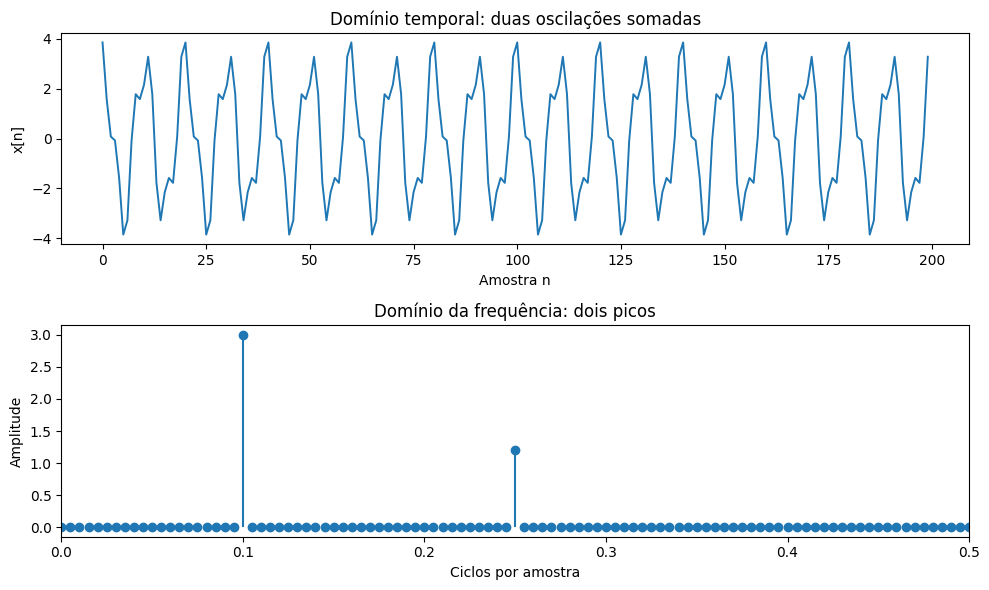

Amplitudes estimadas: 3.0 1.2000000000000004


In [1]:
import numpy as np
import matplotlib.pyplot as plt
N = 200
n = np.arange(N)
x = 3*np.cos(2*np.pi*0.10*n) + 1.2*np.cos(2*np.pi*0.25*n + np.pi/4)
fs = 1.0  # uma observação por unidade de tempo
freq = np.fft.rfftfreq(N, d=1/fs)
X = np.fft.rfft(x)
amp = 2*np.abs(X)/N
amp[0] = np.abs(X[0])/N
if N % 2 == 0:
    amp[-1] = np.abs(X[-1])/N
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6))
ax1.plot(n, x, lw=1.4)
ax1.set(xlabel='Amostra n', ylabel='x[n]', title='Domínio temporal: duas oscilações somadas')
ax2.stem(freq, amp, basefmt=' ')
ax2.set(xlim=(0, .5), xlabel='Ciclos por amostra', ylabel='Amplitude', title='Domínio da frequência: dois picos')
plt.tight_layout(); plt.show()
print('Amplitudes estimadas:', amp[np.argmin(abs(freq-.10))], amp[np.argmin(abs(freq-.25))])
assert np.allclose([amp[np.argmin(abs(freq-.10))],amp[np.argmin(abs(freq-.25))]],[3,1.2],atol=1e-11)

**Interpretação esperada.** Os dois picos aparecem em $0{,}10$ e $0{,}25$ ciclos por amostra; suas alturas são $3$ e $1{,}2$ graças ao alinhamento com a grade e à normalização adotada. Este gráfico é de **amplitude da DFT**, não uma estimativa apresentada como densidade espectral teórica.

### 8. Laboratório Python — do tempo para o espectro com ruído

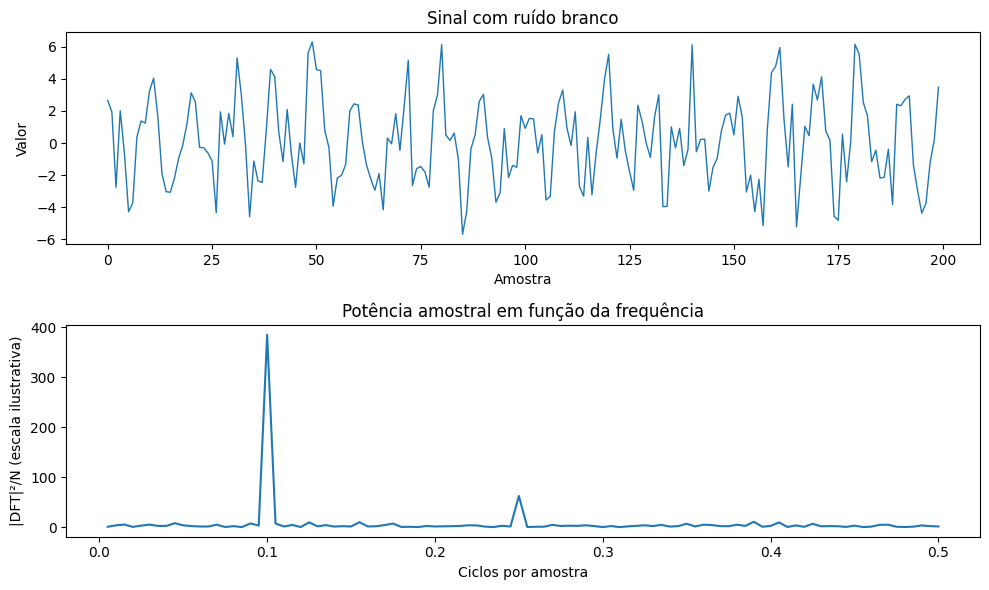

In [2]:
rng = np.random.default_rng(2026)
y = x + rng.normal(0, 1.5, N)
Y = np.fft.rfft(y - y.mean())
periodogram_raw = np.abs(Y)**2/N
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6))
ax1.plot(n, y, lw=1)
ax1.set(xlabel='Amostra', ylabel='Valor', title='Sinal com ruído branco')
ax2.plot(freq[1:], periodogram_raw[1:])
ax2.set(xlabel='Ciclos por amostra', ylabel='|DFT|²/N (escala ilustrativa)', title='Potência amostral em função da frequência')
plt.tight_layout(); plt.show()

**Interpretação.** Os picos continuam visíveis, mas a dispersão do ruído aparece ao longo de muitas frequências. Esse gráfico é uma medida baseada na DFT da **amostra finita**; sua escala não foi definida como estimador final de densidade espectral. A normalização estatística precisa será tratada na seção sobre periodograma.

### 9. Limitações e cuidados

1. A DFT pressupõe amostragem aproximadamente regular; dados irregulares exigem métodos apropriados ou procedimentos justificados de regularização.
2. Alterações ao longo do tempo podem ser ocultadas em uma FFT calculada sobre a amostra inteira.
3. Tendências e sazonalidades muito fortes podem dominar o gráfico de frequências sem que isso represente a dependência estacionária que desejamos modelar.
4. Janela finita, resolução $f_s/N$, leakage, aliasing e escolha da escala afetam a interpretação.
5. A análise espectral teórica do livro parte de processos fracamente estacionários (com as hipóteses indicadas para a densidade). Não devemos aplicar automaticamente suas conclusões a uma série não estacionária.

### 10. Exercícios para construir autonomia

**Exercício 1.** Escreva uma senoide de amplitude $4$, frequência $0{,}125$ ciclos por amostra e fase $\pi/6$. Qual é o período em amostras? Faça o gráfico para 64 pontos.

**Exercício 2.** Para $x=(1,1,1,1)$, calcule todos os quatro coeficientes da DFT manualmente. Interprete $X_0$.

**Exercício 3.** Repita o laboratório com frequência $0{,}103$ no lugar de $0{,}10$. Antes de executar, formule uma hipótese sobre o formato do espectro; depois compare.

**Exercício 4.** Explique por escrito a diferença entre amplitude de Fourier, periodograma e densidade espectral populacional. Evite tratar como sinônimos.

**Exercício 5.** Altere o sinal para conter uma frequência apenas na primeira metade da amostra. A FFT global indica o instante de ocorrência? Que abordagem dos módulos futuros permitiria localizá-lo?

**Pseudocódigo sugerido:** definir $N$ e frequências → construir vetor de instantes → gerar senoides → somar → aplicar `rfft` → criar grade com `rfftfreq` → ajustar normalização → interpretar picos. Implemente primeiro sem consultar uma solução pronta.

### 11. Síntese e conexão com a próxima seção

No domínio temporal observamos a trajetória; no domínio da frequência, observamos a composição por oscilações. A DFT descreve uma amostra, mas a **densidade espectral de um processo estacionário** precisa ser definida matematicamente por suas autocovariâncias. Essa é a tarefa da Seção 9.2.